# 02 · First Realtime session: text in, audio out

Before using the mic, learn the **conversation protocol** on its own. It is just JSON events over one WebSocket:

```
client → session.update          (configure: instructions, voice, audio format, VAD)
client → conversation.item.create (a user message)
client → response.create          ("now answer")
server → response.output_audio.delta × N   (base64 PCM16 chunks: play them as they arrive)
server → response.done            (usage / tokens)
```
Helpers: `live/realtime.py` (new), `live/audio.py` (from 01).

In [1]:
import json
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from live import audio, config, realtime

## 1. Where we connect
The model name is a URL query parameter. The key travels in an `Authorization` header and is never printed.

In [2]:
config.URL

'wss://api.openai.com/v1/realtime?model=gpt-realtime-mini'

## 2. Open the socket
One long-lived, two-way connection. Everything after this point happens on it.

In [3]:
ws = await realtime.connect()
ws.state

<State.OPEN: 1>

## 3. The server speaks first: `session.created`
It shows the default configuration we're about to override.

In [4]:
created = await realtime.recv(ws)
created['type'], created['session']['model'], created['session']['audio']['output']['voice']

('session.created', 'gpt-realtime-mini', 'alloy')

## 4. Configure the session
This dict is the whole "personality + plumbing" of the assistant:

In [5]:
session = realtime.session_config("You are a friendly voice tutor. Answer in one or two short sentences.")
session

{'type': 'realtime',
 'instructions': 'You are a friendly voice tutor. Answer in one or two short sentences.',
 'audio': {'input': {'format': {'type': 'audio/pcm', 'rate': 24000},
   'turn_detection': {'type': 'semantic_vad'}},
  'output': {'format': {'type': 'audio/pcm', 'rate': 24000},
   'voice': 'marin'}}}

In [6]:
await realtime.send(ws, {"type": "session.update", "session": session})
updated = await realtime.recv(ws)
updated['type'], updated['session']['instructions'], updated['session']['audio']['output']['voice']

('session.updated',
 'You are a friendly voice tutor. Answer in one or two short sentences.',
 'marin')

## 5. Add a user message to the conversation
The server keeps the conversation history. We only append items to it. Nothing is generated yet.

In [7]:
item = realtime.user_text("In one sentence: why does streaming make a voice assistant feel fast?")
item

{'type': 'conversation.item.create',
 'item': {'type': 'message',
  'role': 'user',
  'content': [{'type': 'input_text',
    'text': 'In one sentence: why does streaming make a voice assistant feel fast?'}]}}

In [8]:
await realtime.send(ws, item)
ack = await realtime.recv(ws)
ack['type'], ack['item']['role']

('conversation.item.added', 'user')

## 6. Ask for a response, then collect every event until `response.done`
`_t` = seconds since we asked. This shows the latency.

In [9]:
await realtime.send(ws, {"type": "response.create"})
events = await realtime.collect(ws, until="response.done")
Counter(e['type'] for e in events)

Counter({'response.output_audio_transcript.delta': 21,
         'response.output_audio.delta': 17,
         'conversation.item.done': 2,
         'response.created': 1,
         'response.output_item.added': 1,
         'conversation.item.added': 1,
         'response.content_part.added': 1,
         'response.output_audio.done': 1,
         'response.output_audio_transcript.done': 1,
         'response.content_part.done': 1,
         'response.output_item.done': 1,
         'response.done': 1})

The event timeline: one small header event, then a stream of deltas, then `done`. Audio deltas arrive **while the model is still generating**, which is the core of feeling live.

In [10]:
[(e['_t'], e['type']) for e in events if e['type'] != 'response.output_audio_transcript.delta'][:8]

[(0.0, 'conversation.item.done'),
 (0.301, 'response.created'),
 (0.49, 'response.output_item.added'),
 (0.49, 'conversation.item.added'),
 (0.5, 'response.content_part.added'),
 (0.773, 'response.output_audio.delta'),
 (0.961, 'response.output_audio.delta'),
 (1.062, 'response.output_audio.delta')]

## 7. Latency: time to first audio vs. total
Playback can start at the first delta. The user doesn't wait for the total.

In [11]:
deltas = [e for e in events if e['type'] == 'response.output_audio.delta']
first_audio_s, total_s = deltas[0]['_t'], events[-1]['_t']
first_audio_s, total_s, len(deltas)

(0.773, 1.584, 17)

## 8. Rebuild the audio
Each delta is a base64 PCM16 chunk, the mirror image of notebook 01.

In [12]:
chunk_sizes = [len(audio.from_b64(d['delta'])) for d in deltas]
chunk_sizes[:5], sum(chunk_sizes)

([19200, 19200, 19200, 19200, 19200], 324000)

In [13]:
reply = audio.from_bytes(b''.join(audio.from_b64(d['delta']) for d in deltas))
reply.shape, reply.dtype, round(len(reply) / audio.RATE, 2)   # samples, type, seconds of speech

((162000,), dtype('int16'), 6.75)

## 9. What it said (the model also streams a transcript of its own speech)

In [14]:
transcript = ''.join(e['delta'] for e in events if e['type'] == 'response.output_audio_transcript.delta')
transcript

'Streaming makes a voice assistant feel fast because it processes data in small chunks in real-time, reducing delays.'

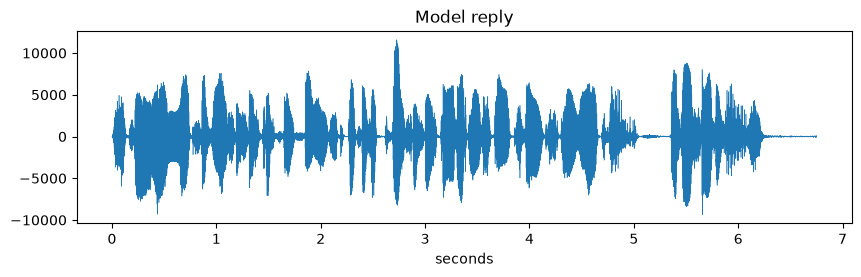

In [15]:
t = np.arange(len(reply)) / audio.RATE
plt.figure(figsize=(10, 2.5)); plt.plot(t, reply, lw=0.4)
plt.xlabel('seconds'); plt.title('Model reply'); plt.show()

In [16]:
Audio(reply, rate=audio.RATE)

In [17]:
audio.play(reply)

## 10. Cost: `response.done` carries token usage
Audio tokens cost far more than text tokens. Keep this in mind for always-on mics.

In [18]:
events[-1]['response']['status'], events[-1]['response']['usage']

('completed',
 {'total_tokens': 203,
  'input_tokens': 33,
  'output_tokens': 170,
  'input_token_details': {'text_tokens': 33,
   'audio_tokens': 0,
   'image_tokens': 0,
   'cached_tokens': 0,
   'cached_tokens_details': {'text_tokens': 0,
    'audio_tokens': 0,
    'image_tokens': 0}},
  'output_token_details': {'text_tokens': 35, 'audio_tokens': 135}})

In [19]:
await ws.close()
ws.state

<State.CLOSED: 3>

## Takeaways
- A "live" session = one WebSocket + a handful of JSON event types.
- The server owns the conversation history. We append items and ask for responses.
- Latency that matters = **time to first audio delta**, not total generation time.

**Next (03):** replace the text message with the live mic stream (`input_audio_buffer.append`) and let server VAD decide when you've finished speaking.